# Журнал состояний: все результаты — окно с 2013-01-01

Ноутбук собирает готовые результаты из `out_states\2013\` и `out_states\flags\`.
Ничего не пересчитывает: после досчёта тайм-аутов достаточно выполнить его заново.

**Флаги журнала** во всех расчётах, кроме перебора флагов:
`SHORT_CUSTODY_DAYS` = 15, `LONG_CUSTODY_DAYS` = 365.

| Раздел | Что | Где посчитано |
|---|---|---|
| 1 | Все майнеры, сеть строится и проверяется на всём журнале | `petri_states.ipynb`, шаг 3 |
| 2 | Лучшие майнеры, люди train/test 80/20, alignments | `petri_states_eval_2013.ipynb`, `run_split.py` |
| 3 | Досчёт тайм-аутов alignments с большим лимитом | `retry_timeouts.py` |
| 4 | Сводка по лучшим моделям | собирается здесь из 1–3 |
| 5 | Рисунки сетей лучших моделей и DFG | `petri_states.ipynb`, шаг 3 |
| 6 | Флаги `SHORT` / `LONG` | `petri_states_flags.ipynb` |
| 7 | Выводы | |

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

EXP = "2013"
OUT = Path("out_states") / EXP
FLAGS = Path("out_states") / "flags"
BEST = ["flower", "DFG_p0.05", "HM_dep0.95", "SplitMiner", "IM_noise0.2"]
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)


def read_jsonl(p):
    p = Path(p)
    if not p.exists():
        return pd.DataFrame()
    return pd.DataFrame([json.loads(l) for l in p.read_text(encoding="utf-8").splitlines() if l.strip()])


mq = pd.read_csv(OUT / "model_quality.csv")
se = read_jsonl(OUT / "split_eval.jsonl")
rt = pd.concat([read_jsonl(p) for p in sorted(OUT.glob("split_eval_retry*s.jsonl"))] or [pd.DataFrame()],
               ignore_index=True)
print("файлы:", OUT / "model_quality.csv", OUT / "split_eval.jsonl",
      *[p.name for p in sorted(OUT.glob("split_eval_retry*s.jsonl"))], sep="\n  ")

файлы:
  out_states/2013/model_quality.csv
  out_states/2013/split_eval.jsonl
  split_eval_retry600s.jsonl


## 1. Все майнеры: сеть строится и проверяется на всём журнале

Без разбиения train/test и без alignments: насколько модель описывает данные, а не прогноз.

- `fitness_tbr` — fitness token-based replay; `pct_fit_traces_tbr` — % трасс, прошедших без ошибок;
- `precision_etc` — precision ETC (escaping edges);
- `precision_norm = (P − P_flower) / (1 − P_flower)`: 0 — не лучше цветочной сети, 1 — максимум;
- `f1 = 2·fitness·precision / (fitness + precision)`.

In [2]:
cols = ["model", "places", "transitions", "silent", "fitness_tbr", "pct_fit_traces_tbr",
        "precision_etc", "precision_flower", "precision_norm", "f1"]
mq[cols].sort_values("f1", ascending=False).set_index("model")

,places,transitions,silent,fitness_tbr,pct_fit_traces_tbr,precision_etc,precision_flower,precision_norm,f1
model,,,,,,,,,
DFG_p0.05,12,27,1,0.966,69.806,0.815,0.421,0.681,0.884
HM_dep0.95,16,36,26,0.982,60.903,0.675,0.421,0.439,0.800
HM_dep0.9,17,38,28,0.982,60.938,0.670,0.421,0.430,0.796
HM_dep0.99,16,37,27,0.982,60.956,0.668,0.421,0.427,0.795
SplitMiner,19,34,24,0.772,6.394,0.813,0.421,0.678,0.792
DFG_p0.0,12,72,1,1.000,100.000,0.527,0.421,0.183,0.690
IM_noise0.2,35,44,34,1.000,99.725,0.442,0.421,0.036,0.613
IM_noise0.0,37,48,38,1.000,100.000,0.436,0.421,0.026,0.607
POWL,24,27,17,1.000,100.000,0.422,0.421,0.003,0.594


## 2. Лучшие майнеры: train/test 80/20 и alignments

- люди делятся 80/20 (seed 42): сеть строится на train, метрики считаются на test;
- alignments — на **всём** test, лимит **120 с** на вариант трассы;
  варианты, не уложившиеся в лимит, в alignment fitness не входят (столбец `align_timeout`);
- перед alignments проверяется easy soundness: если финальная разметка недостижима, alignments не определены.

In [3]:
cols = [k for k in ["model", "places", "transitions", "silent", "train_traces", "test_traces",
                    "fitness_tbr_train", "fitness_tbr_test", "pct_fit_traces_tbr_test", "precision_etc_test",
                    "easy_sound", "fitness_align_test", "pct_fit_traces_align_test", "align_traces",
                    "align_timeout", "align_max_sec_trace", "note"] if k in se.columns]
se[cols].set_index("model")

,places,transitions,silent,train_traces,test_traces,fitness_tbr_train,fitness_tbr_test,pct_fit_traces_tbr_test,precision_etc_test,easy_sound,fitness_align_test,pct_fit_traces_align_test,align_traces,align_timeout,align_max_sec_trace
model,,,,,,,,,,,,,,,
flower,3,12,2,9022,2255,1.000,1.000,100.000,0.358,NaN,NaN,NaN,NaN,NaN,120
DFG_p0.05,12,27,1,9022,2255,0.966,0.966,71.486,0.759,NaN,0.964,71.384,2255.0,1.0,120
HM_dep0.95,16,36,26,9022,2255,0.982,0.982,61.419,0.602,NaN,0.944,61.419,2255.0,0.0,120
SplitMiner,19,34,24,9022,2255,0.772,0.775,6.253,0.773,NaN,0.633,6.272,2255.0,7.0,120
IM_noise0.2,35,44,34,9022,2255,1.000,1.000,99.867,0.374,True,1.000,99.858,2255.0,141.0,120


## 3. Попытка досчёта alignments с большим лимитом

**Как шёл расчёт:**
1. Alignments на всём test с лимитом **120 с** на вариант трассы (раздел 2); варианты, не уложившиеся в лимит, —
   тайм-ауты, в alignment fitness они не входят.
2. Тайм-ауты пересчитывались с лимитом **600 с** (`retry_timeouts.py`, папка `align_ckpt` → `align_ckpt_retry600s`);
   готовые варианты не пересчитывались, порядок моделей: DFG p0.05 → Split Miner → IM 0.2.
3. **Досчёт остановлен 04.11.2026 в 20:42** — ресурсы отданы пересчёту журнала версии 2
   (`petri_states_v2_results_{2013,all}.ipynb`). Контрольные точки сохранены: при запуске `retry_timeouts.py`
   досчёт продолжится с места.

Таблица ниже собирается по контрольным точкам:
- `тайм-аутов при лимите` — трасс test, не уложившихся в исходный лимит;
- `перепроверено вариантов` / `выровнено трасс` — сколько из них пересчитано с большим лимитом и сколько выровнялось;
- `не досчитано трасс`, `доля test` — сколько трасс так и не вошло в alignment fitness;
- `alignment fitness сейчас` — с учётом всего, что досчитано (в том числе для моделей, досчёт которых не закончен).

HM 0.95 на всей истории — не тайм-ауты: сеть не easy sound, alignments для неё не определены.

In [4]:
BASE = OUT / "align_ckpt"
RETRY = OUT / "align_ckpt_retry600s"
rows = []
for m in BEST[1:]:
    b = read_jsonl(BASE / f"{m}_align.jsonl")
    if b.empty:
        continue
    r = read_jsonl(RETRY / f"{m}_align.jsonl")
    to = b[b.timeout]
    rr = r.set_index("i") if not r.empty else pd.DataFrame(columns=["timeout", "n"])
    ok_retry = rr[~rr.timeout.astype(bool)] if len(rr) else rr
    allr = pd.concat([b[~b.timeout].set_index("i"), ok_retry])
    sound = se.set_index("model").get("easy_sound", pd.Series(dtype=object)).get(m)
    fit = None if allr.empty or sound is False else 1 - (allr.cost * allr.n).sum() / (allr.bwc * allr.n).sum()
    not_done = int(to.n.sum() - ok_retry.n.sum()) if len(rr) else int(to.n.sum())
    rows.append({"модель": m, "трасс test": int(b.n.sum()),
                 "тайм-аутов при лимите": int(to.n.sum()), "вариантов с тайм-аутом": len(to),
                 "перепроверено вариантов": len(rr), "выровнено трасс": int(ok_retry.n.sum()) if len(rr) else 0,
                 "не досчитано трасс": not_done, "доля test, %": round(100 * not_done / b.n.sum(), 1),
                 "alignment fitness сейчас": fit,
                 "примечание": "не easy sound — alignments не определены" if sound is False else "тайм-аутов нет" if to.empty else
                               ("досчёт закончен" if m in set(rt.get("model", [])) else
                                ("досчёт остановлен" if len(rr) else "досчёт не начинался"))})
pd.DataFrame(rows).set_index("модель").round(3)

,трасс test,тайм-аутов при лимите,вариантов с тайм-аутом,перепроверено вариантов,выровнено трасс,не досчитано трасс,"доля test, %",alignment fitness сейчас,примечание
модель,,,,,,,,,
DFG_p0.05,2255,1,1,1,0,1,0.0,0.964,досчёт закончен
HM_dep0.95,2255,0,0,0,0,0,0.0,0.944,тайм-аутов нет
SplitMiner,2255,7,7,7,6,1,0.0,0.633,досчёт закончен
IM_noise0.2,2255,141,140,30,24,117,5.2,1.000,досчёт остановлен


In [5]:
# модели, для которых досчёт закончен: итог (лимит, сколько тайм-аутов было и осталось)
if not rt.empty:
    display(rt[["model", "retry_of", "align_max_sec_trace", "align_timeout_before", "align_timeout",
                "align_traces", "fitness_align_test", "pct_fit_traces_align_test", "finished"]].set_index("model"))

,retry_of,align_max_sec_trace,align_timeout_before,align_timeout,align_traces,fitness_align_test,pct_fit_traces_align_test,finished
model,,,,,,,,
DFG_p0.05,120,600,1,1,2255,0.964,71.384,2026-11-04 13:55
SplitMiner,120,600,7,1,2255,0.633,6.256,2026-11-04 14:24


## 4. Сводка по лучшим моделям

Весь журнал (раздел 1) + test (раздел 2) + итоговые alignments: если для модели есть досчёт
с большим лимитом (раздел 3), берётся он. Precision нормируется на цветочную сеть **на test**.

In [6]:
P_FLOWER = se.loc[se.model == "flower", "precision_etc_test"].iloc[0]
rows = []
for m in BEST:
    q = mq.set_index("model").loc[m] if m in set(mq.model) else None
    s = se.set_index("model").loc[m]
    r = rt[rt.model == m].sort_values("align_max_sec_trace").iloc[-1] if (not rt.empty and m in set(rt.model)) else None
    a = r if r is not None else s
    fa = a.get("fitness_align_test")
    p = s["precision_etc_test"]
    rows.append({
        "модель": m,
        "F1 весь журнал": None if q is None else q["f1"],
        "fitness TBR train": s["fitness_tbr_train"],
        "fitness TBR test": s["fitness_tbr_test"],
        "precision test": p,
        "precision норм. test": None if m == "flower" else (p - P_FLOWER) / (1 - P_FLOWER),
        "F1 TBR test": None if m == "flower" else 2 * s["fitness_tbr_test"] * p / (s["fitness_tbr_test"] + p),
        "easy sound": s.get("easy_sound"),
        "alignment fitness test": None if m == "flower" else fa,
        "F1 alignments test": None if (m == "flower" or pd.isna(fa)) else 2 * fa * p / (fa + p),
        "лимит, с": None if m == "flower" else a.get("align_max_sec_trace"),
        "доля тайм-аутов": None if (m == "flower" or pd.isna(a.get("align_timeout"))) else a["align_timeout"] / s["test_traces"],
    })
summary = pd.DataFrame(rows).set_index("модель")
summary["доля тайм-аутов"] = (summary["доля тайм-аутов"] * 100).round(1)
summary = summary.rename(columns={"доля тайм-аутов": "тайм-аутов, %"})
summary.round(3)

,F1 весь журнал,fitness TBR train,fitness TBR test,precision test,precision норм. test,F1 TBR test,easy sound,alignment fitness test,F1 alignments test,"лимит, с","тайм-аутов, %"
модель,,,,,,,,,,,
flower,0.592,1.000,1.000,0.358,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DFG_p0.05,0.884,0.966,0.966,0.759,0.625,0.850,NaN,0.964,0.849,600.0,0.0
HM_dep0.95,0.800,0.982,0.982,0.602,0.381,0.747,NaN,0.944,0.736,120.0,0.0
SplitMiner,0.792,0.772,0.775,0.773,0.647,0.774,NaN,0.633,0.696,600.0,0.0
IM_noise0.2,0.613,1.000,1.000,0.374,0.024,0.544,True,1.000,0.544,120.0,6.3


## 5. Сети лучших моделей и DFG

Сети построены на всём журнале (раздел 1). DFG — все пары соседних состояний с частотами, без фильтра.

DFG_p0.05


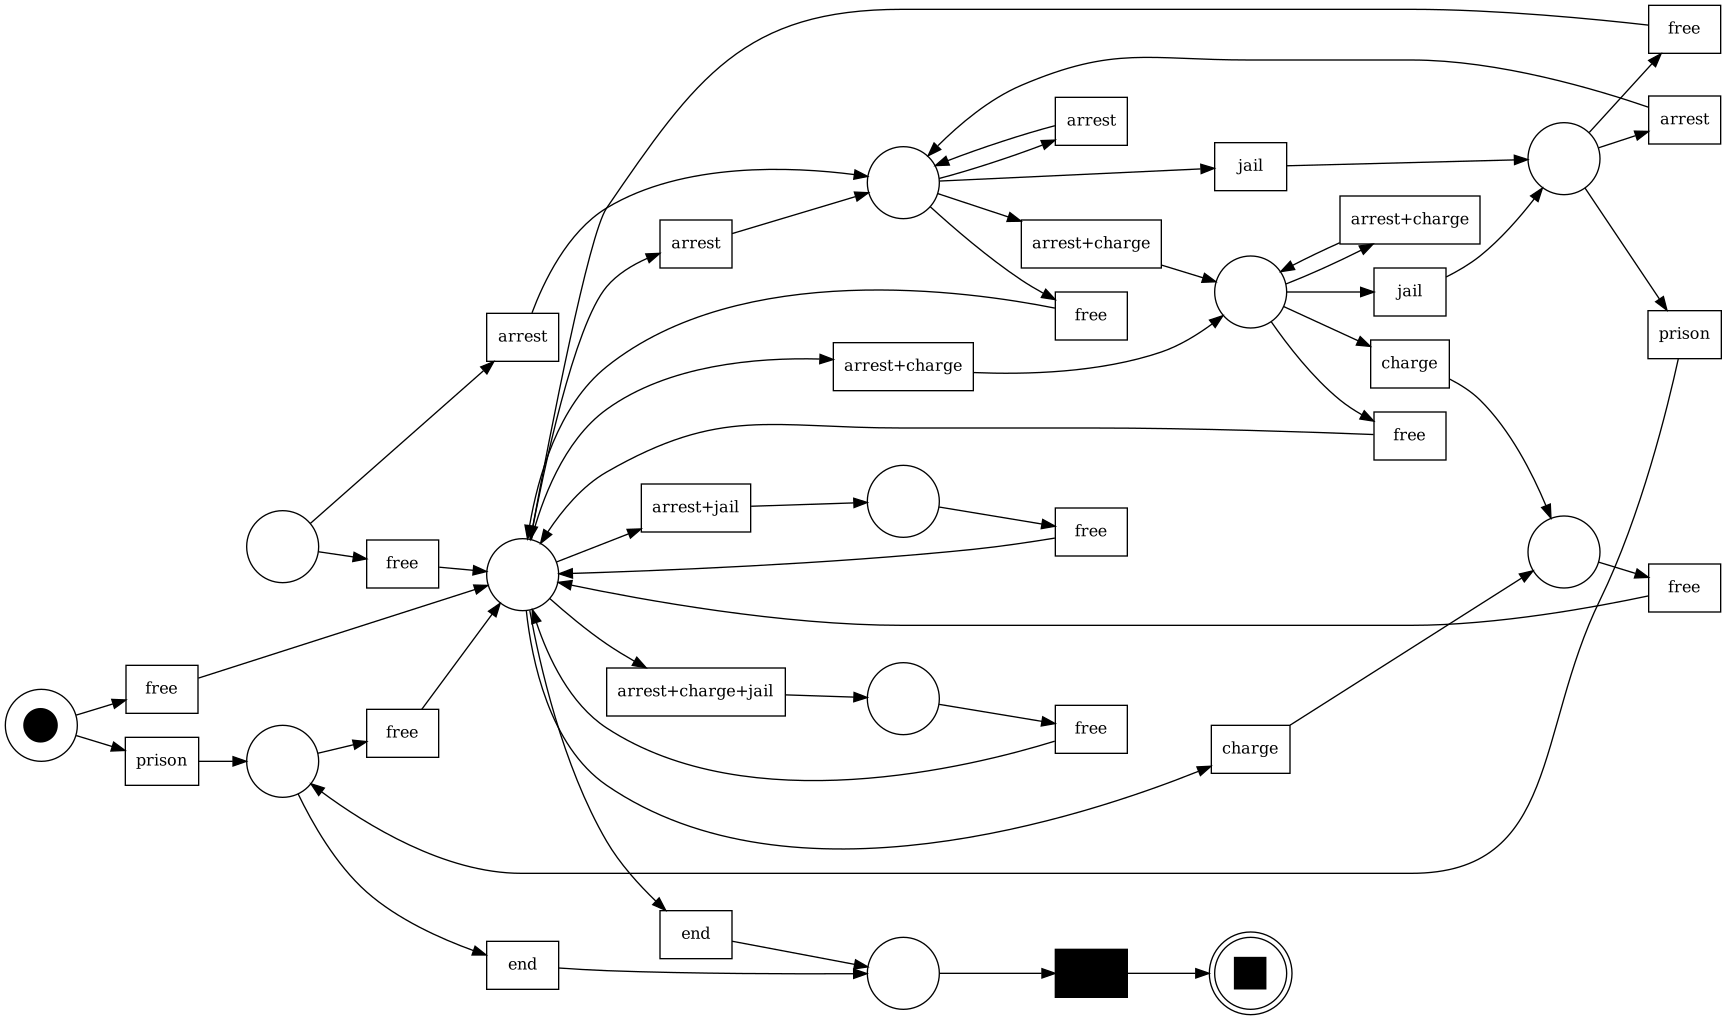

HM_dep0.95


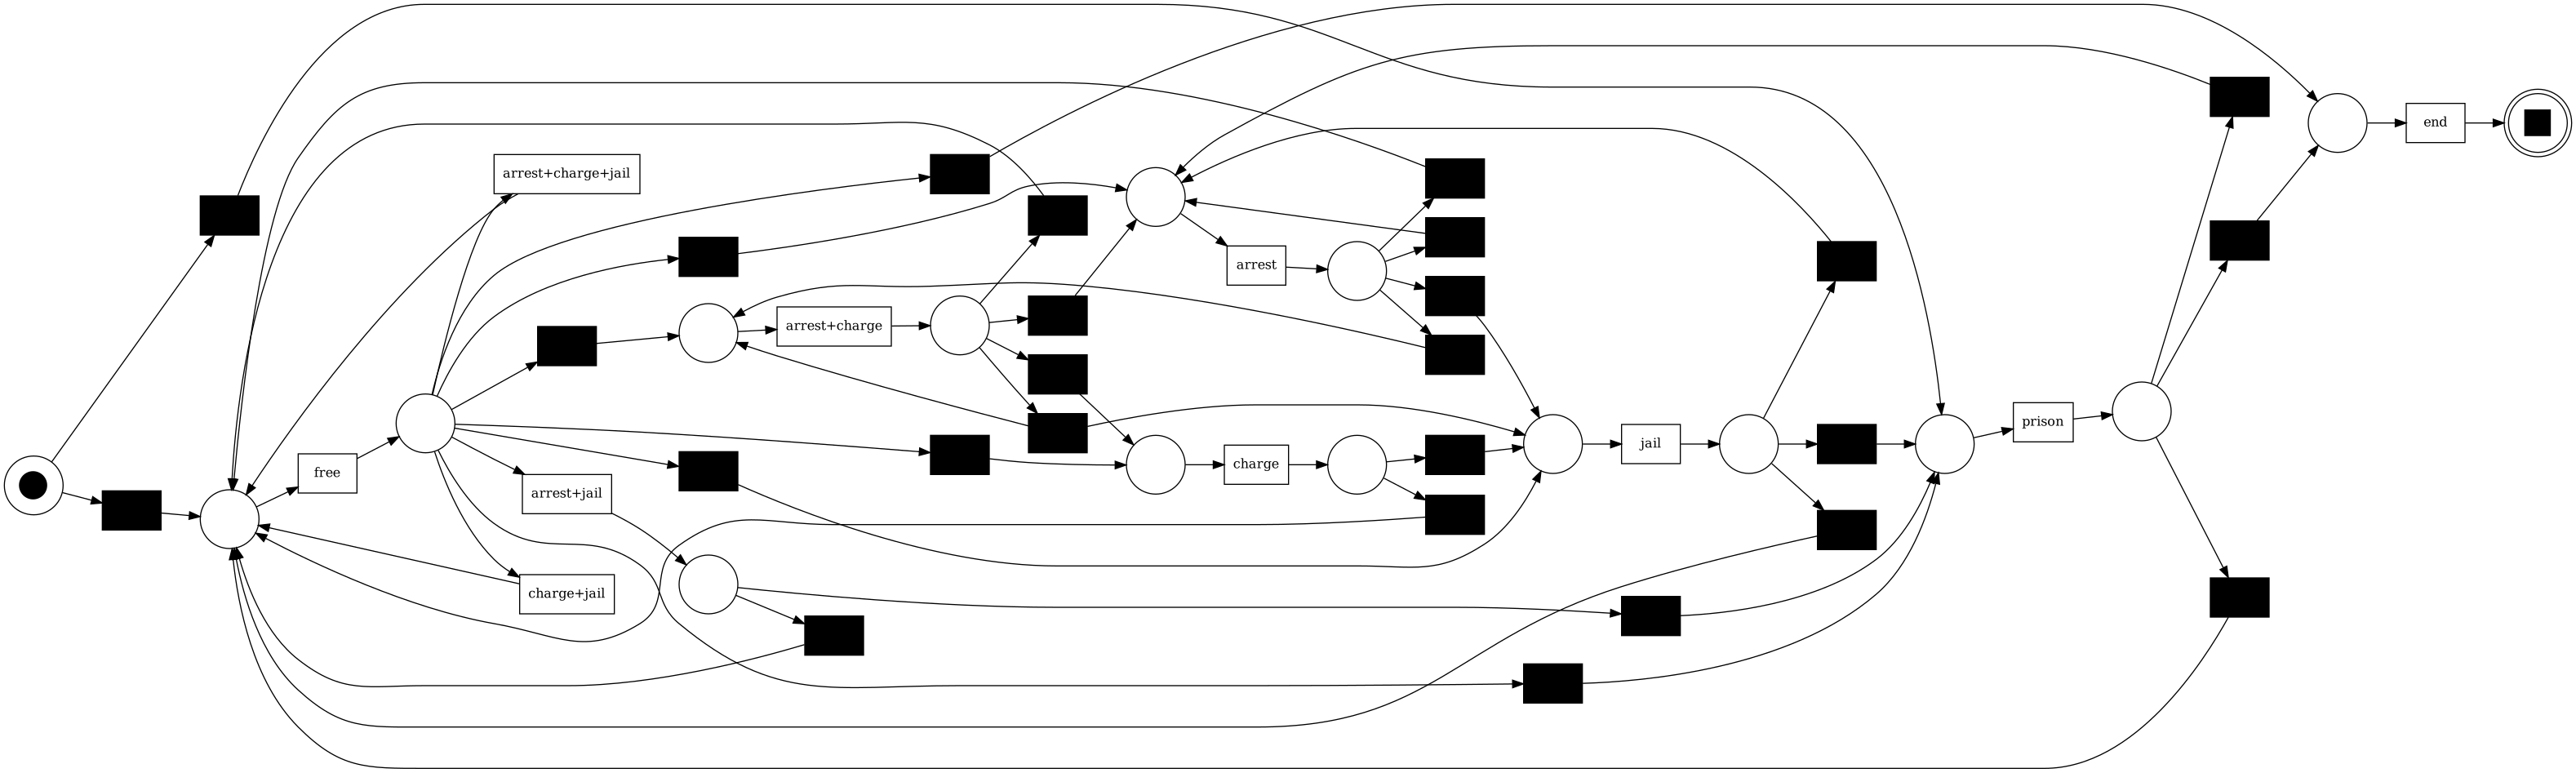

SplitMiner


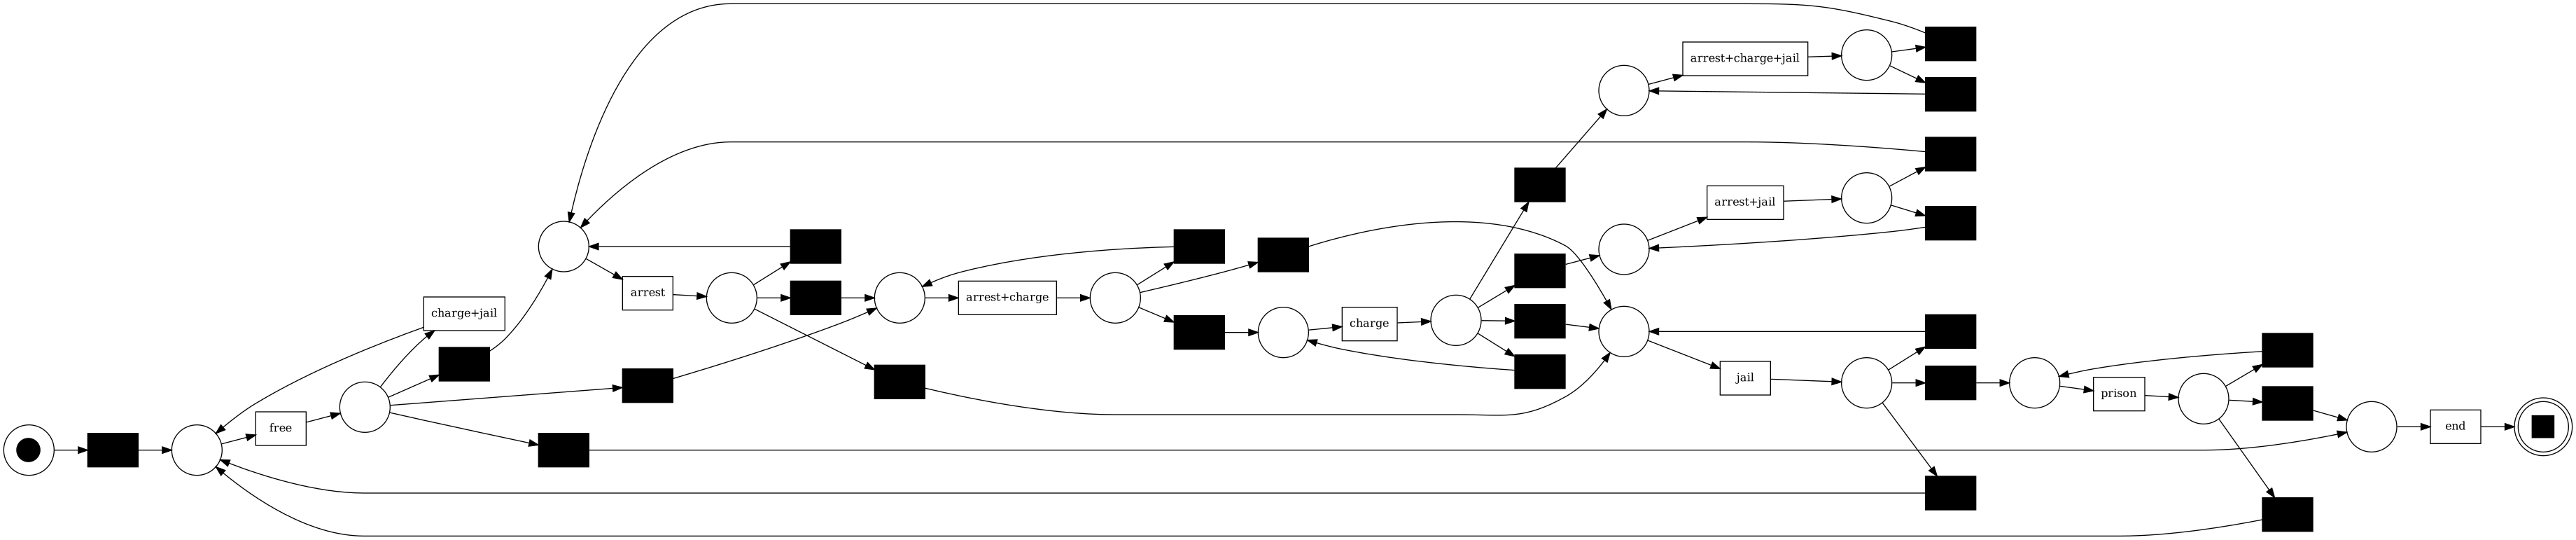

IM_noise0.2


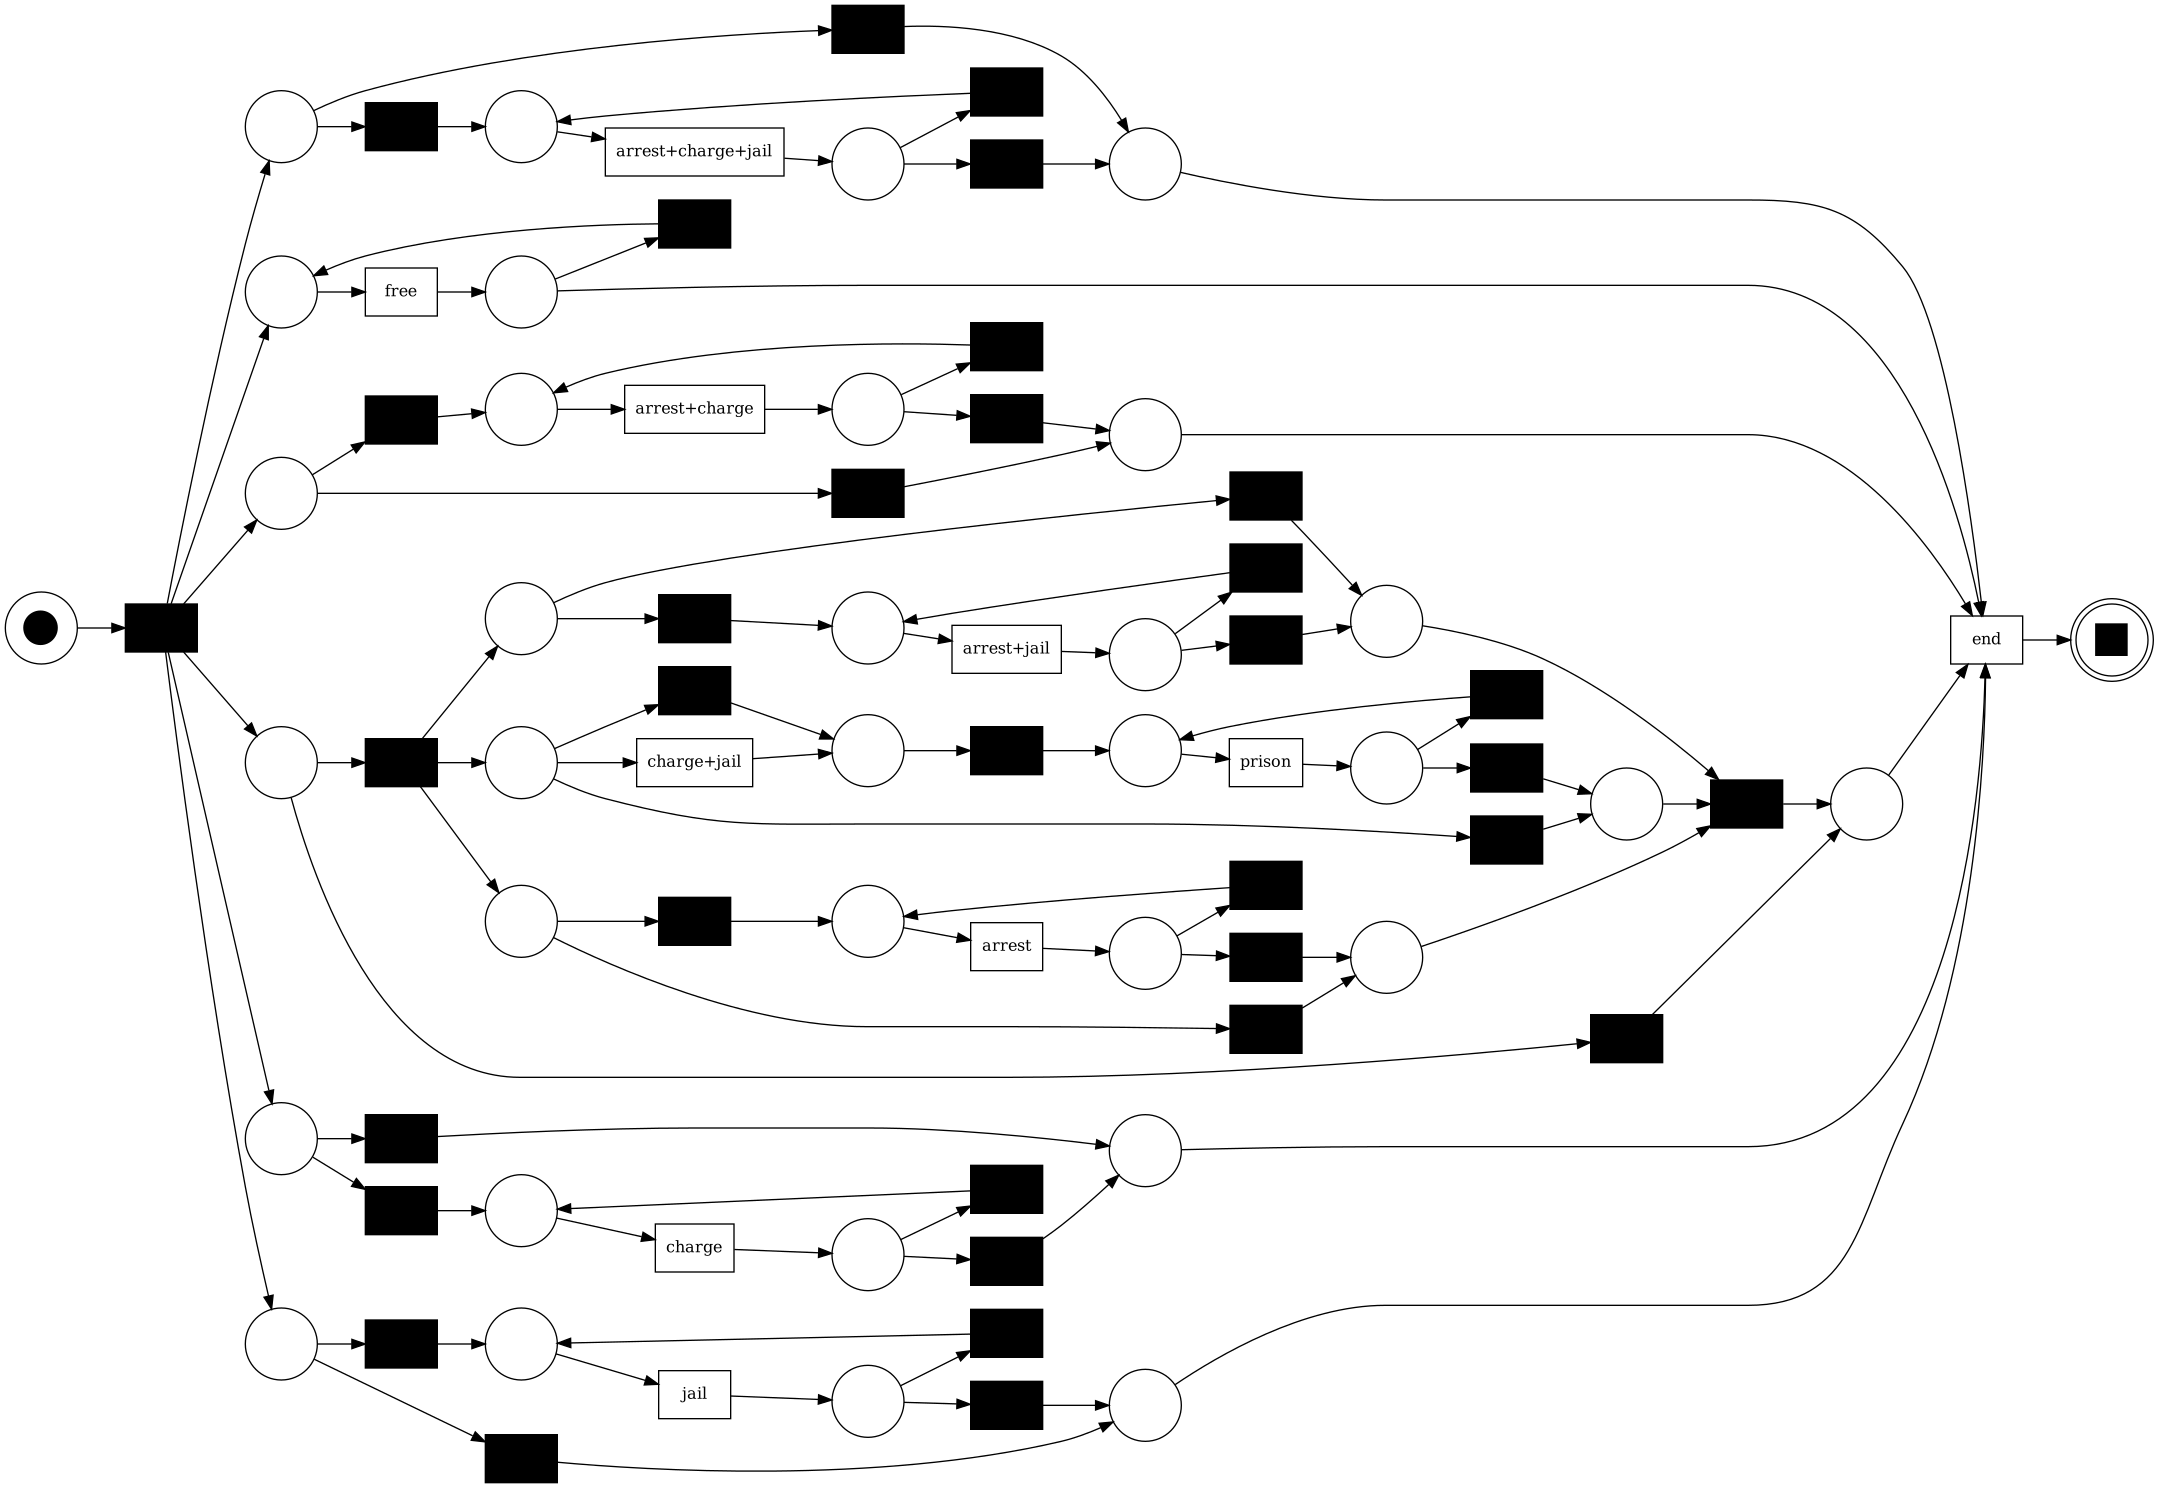

DFG, частоты


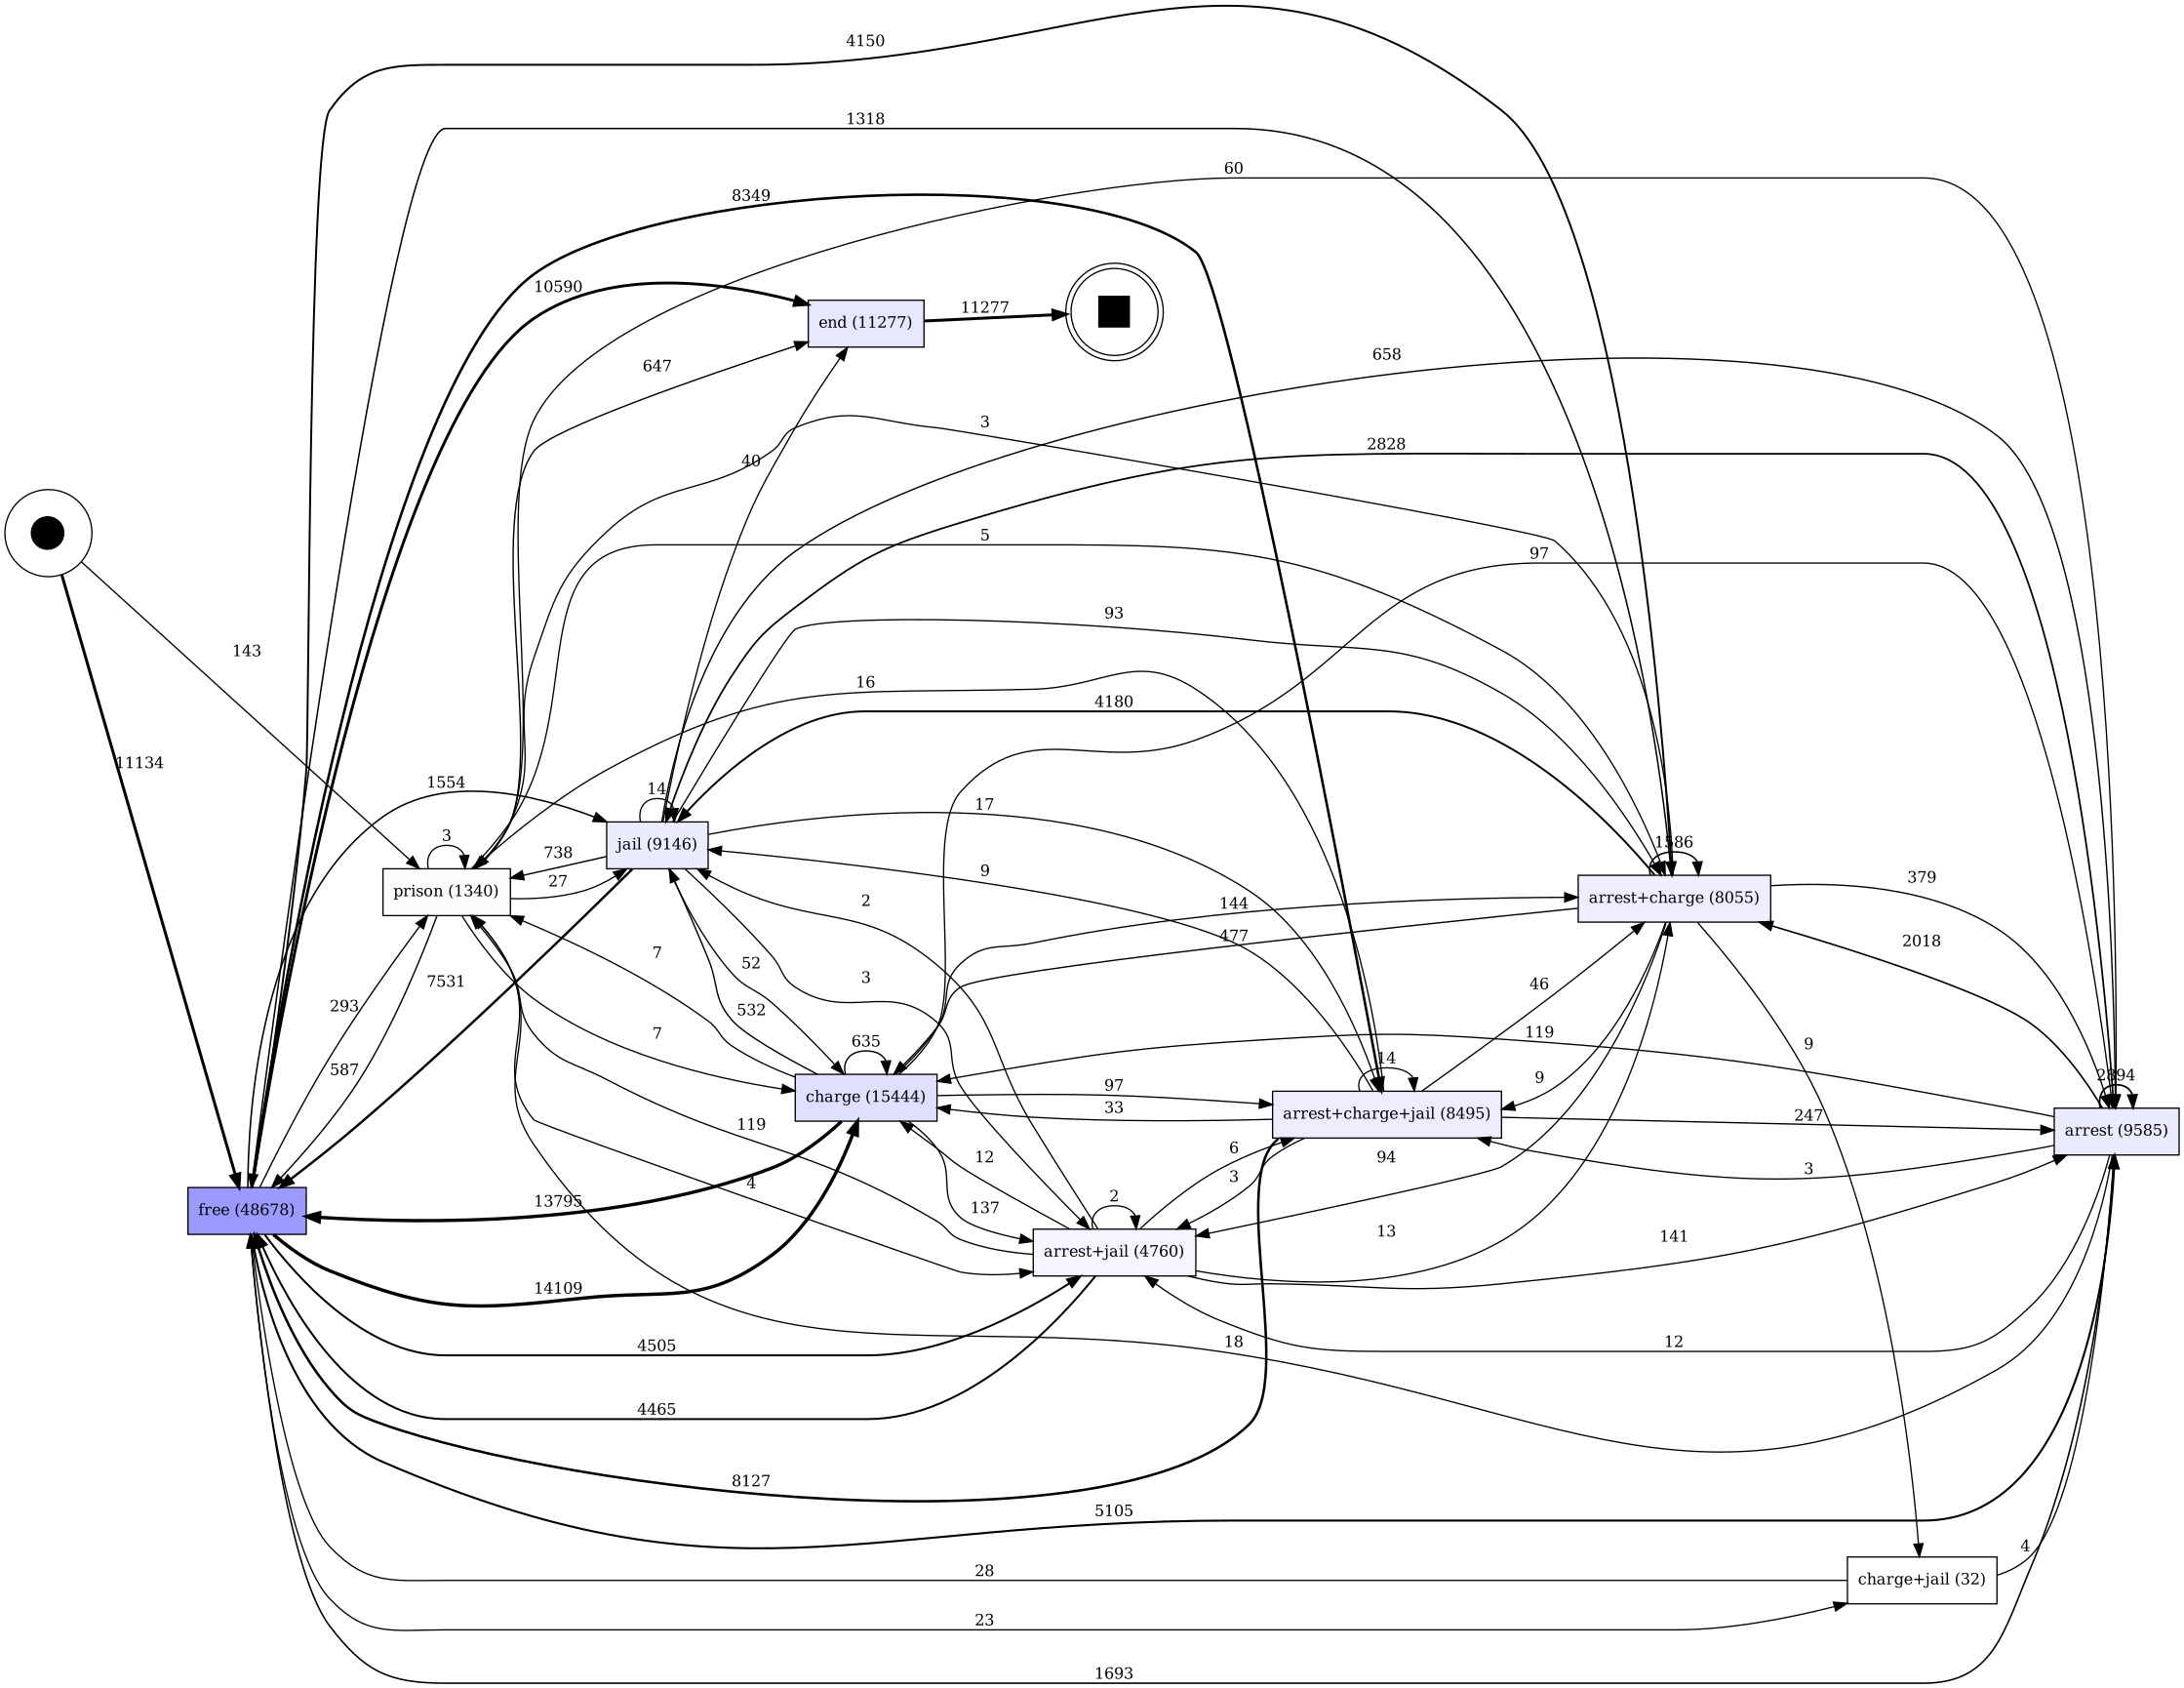

In [7]:
for m in BEST[1:]:
    p = OUT / f"net_{m}.png"
    if p.exists():
        print(m)
        display(Image(filename=str(p), width=1000))
p = OUT / "dfg_frequency.png"
if p.exists():
    print("DFG, частоты")
    display(Image(filename=str(p), width=1000))

## 6. Флаги `SHORT_CUSTODY_DAYS` и `LONG_CUSTODY_DAYS`

Перебор флагов (`petri_states_flags.ipynb`, шаг 5): сеть на train, на test — TBR fitness и ETC precision,
без alignments; `long = 100000` — правило 5 выключено. Модели: DFG p0.05, HM 0.95, Split Miner.

In [8]:
sw = pd.read_csv(FLAGS / "flags_sweep_table.csv")
sw = sw[sw["exp"].astype(str) == "2013-01-01"].drop(columns="exp").sort_values(["seed", "short", "long"])
sw.set_index(["seed", "short", "long"])

F1 DFG_p0.05  F1 HM_dep0.95  F1 SplitMiner  F1 среднее  Pnorm DFG_p0.05  Pnorm HM_dep0.95  Pnorm SplitMiner  variants_test  composite  absorbed  inside
seed short long                                                                                                                                                           
7    5     180            0.849          0.743          0.781       0.791            0.623             0.377             0.666           1160      12806        76    1714
           365            0.852          0.741          0.780       0.791            0.630             0.371             0.668           1155      13228        76    1714
     15    90             0.847          0.740          0.783       0.790            0.616             0.373             0.666           1163      12256       181    1609
           180            0.849          0.742          0.781       0.791            0.622             0.376             0.666           1160      12806       181    1609
           365            0.852          0.743          0.780       0.792            0.628             0.377             0.668           1155      13228       181    1609
           730            0.852          0.741          0.725       0.772            0.646             0.397             0.527           1155      13443       181    1609
42   0     365            0.851          0.749          0.784       0.795            0.623             0.380             0.652           1148      13228         0    1790
     1     365            0.851          0.749          0.784       0.795            0.623             0.380             0.652           1148      13228         0    1790
     2     365            0.851          0.749          0.784       0.795            0.623             0.381             0.652           1147      13228        25    1765
     3     365            0.850          0.749          0.784       0.795            0.622             0.380             0.652           1147      13228        51    1739
     5     180            0.849          0.750          0.776       0.792            0.623             0.390             0.647           1153      12806        76    1714
           270            0.850          0.750          0.775       0.792            0.625             0.389             0.647           1149      13089        76    1714
           365            0.850          0.749          0.784       0.794            0.624             0.383             0.653           1146      13228        76    1714
     7     180            0.849          0.750          0.785       0.795            0.622             0.391             0.654           1153      12806       110    1680
           365            0.850          0.750          0.774       0.791            0.623             0.384             0.645           1146      13228       110    1680
     10    365            0.851          0.746          0.774       0.790            0.625             0.378             0.647           1143      13228       140    1650
     15    7              0.842          0.738          0.790       0.790            0.622             0.383             0.642           1183       8528       181    1609
           15             0.842          0.730          0.785       0.785            0.609             0.362             0.640           1177       9582       181    1609
           30             0.841          0.735          0.784       0.786            0.603             0.365             0.644           1170      10549       181    1609
           60             0.845          0.739          0.780       0.788            0.613             0.373             0.647           1155      11781       181    1609
           90             0.847          0.742          0.778       0.789            0.619             0.378             0.648           1152      12256       181    1609
           120            0.848          0.744          0.777       0.790            0

Медианы времени между состояниями журнала (окно 2013, флаги 15 / 365), дни:

In [9]:
pd.read_csv(FLAGS / "transition_medians_current.csv").set_index("переход")

,n,q25,median,q75
переход,,,,
"составное дело+заключение → следующее (правила 3, 6)",13287,0.95,1.96,15.17
"дело → jail/prison в тот же день (правила 4, 5)",4687,0.17,0.29,0.42
jail/prison без дела → следующее,8197,1.06,6.94,44.35
заключение → дело внутри срока (правило 7),1371,0.94,11.00,33.49
дело внутри срока → возврат (правило 7),1374,1.00,1.00,1.00
возврат → следующее (правило 7),1170,20.00,53.00,142.14


## 7. Выводы (окно 2013)

**Лучшая модель — сеть из DFG с фильтром p ≥ 0.05.**
- alignment fitness на test — 0.964, precision ETC — 0.759, нормированная — 0.625;
- F1 по alignments — 0.849, лучший среди моделей;
- не уложилась в лимит одна трасса (99 событий) даже при 600 с — на итог не влияет.

**Остальные модели:**
- **HM 0.95** — fitness 0.944, но precision 0.602 (нормированная 0.381): разрешает много лишнего;
- **Split Miner** — precision 0.773 (нормированная 0.647, выше всех), но fitness 0.633:
  отбрасывает много поведения, почти ни одна трасса не проходит без ошибок;
- **IM 0.2** — fitness 1.0, но precision почти как у цветочной сети (нормированная 0.024):
  модель почти ничего не запрещает.

**Переобучения нет:** TBR fitness на train и test различается не больше чем на 0.003.

**Флаги:** по перебору на окне 2013 метрики почти не зависят от `SHORT_CUSTODY_DAYS`;
по `LONG_CUSTODY_DAYS` от 180 до 365 дней — плато. Рекомендация: `LONG` = 180, `SHORT` = 15
(подробно — `petri_states_flags.ipynb`). Все таблицы выше посчитаны с флагами 15 / 365.

*Досчёт тайм-аутов остановлен 04.11 (раздел 3): у DFG p0.05, HM 0.95 и Split Miner не досчитано
не больше одной трассы, у IM 0.2 — 117 (5%); вывод по IM 0.2 от этого не изменится (его fitness и так 1.0).*